In [1]:
import sys
sys.path.append("..")

import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn
import skops.io as sio
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBClassifier
from src.data_loader import load_split
from src.preprocessing import CorrelationFilter
from src.feature_selection import ForestTopK

warnings.filterwarnings("ignore", category=ConvergenceWarning)
sns.set_theme()
RANDOM_STATE = 42

X_train, y_train, s_train = load_split("train")      # the test set is not loaded until Cell 6
y0 = y_train - 1                                      # labels 0..5 for every model (XGBoost requires this)
print(X_train.shape, sorted(y0.unique()))

(7352, 561) [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [2]:
def make_lr():
    return LogisticRegression(C=1, max_iter=3000)     # settings of the selected final model

def make_xgb():
    # best XGBoost configuration from Milestone 6 (chosen by training-set grouped CV)
    return XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.8,
                         colsample_bytree=0.5, tree_method="hist", eval_metric="mlogloss",
                         random_state=RANDOM_STATE, n_jobs=-1)

def build(method, k=None):
    # Logistic Regression arms
    if method == "Full":
        return Pipeline([("model", make_lr())])
    if method == "Corr. filter":
        return Pipeline([("corr_filter", CorrelationFilter(0.95)), ("model", make_lr())])
    if method == "PCA":
        return Pipeline([("scaler", StandardScaler()),
                         ("pca", PCA(n_components=k, svd_solver="full", random_state=RANDOM_STATE)),
                         ("model", make_lr())])
    if method == "Importance":
        return Pipeline([("select", ForestTopK(k=k, random_state=RANDOM_STATE)), ("model", make_lr())])
    # XGBoost arms (for the comparison with the base paper)
    if method == "XGB Full":
        return Pipeline([("model", make_xgb())])
    if method == "XGB Corr. filter":
        return Pipeline([("corr_filter", CorrelationFilter(0.95)), ("model", make_xgb())])
    if method == "XGB Importance":
        return Pipeline([("select", ForestTopK(k=k, random_state=RANDOM_STATE)), ("model", make_xgb())])
    raise ValueError(method)

BUDGETS = [200, 100, 30, 10]
configs = [("Full", 561), ("Corr. filter", 253)]
configs += [("PCA", k) for k in BUDGETS] + [("Importance", k) for k in BUDGETS]
configs += [("XGB Full", 561), ("XGB Corr. filter", 253), ("XGB Importance", 100)]
print(len(configs), "configurations")

13 configurations


In [3]:
cv = GroupKFold(n_splits=5)          # groups = volunteers; the same folds for every configuration
fold_scores, rows = {}, []

for method, k in configs:
    t0 = time.time()
    result = cross_validate(build(method, k), X_train, y0, groups=s_train, cv=cv,
                            scoring=["accuracy", "f1_macro"])
    fold_scores[(method, k)] = result["test_accuracy"]
    rows.append({"method": method, "budget": k,
                 "cv_accuracy": result["test_accuracy"].mean(),
                 "cv_std": result["test_accuracy"].std(),
                 "cv_f1_macro": result["test_f1_macro"].mean()})
    print(f"{method:17s} {k:>4d} features | acc {rows[-1]['cv_accuracy']:.4f} "
          f"(std {rows[-1]['cv_std']:.4f}) | {time.time() - t0:.0f}s")

cv_summary = pd.DataFrame(rows)

Full               561 features | acc 0.9387 (std 0.0404) | 7s
Corr. filter       253 features | acc 0.9331 (std 0.0340) | 159s
PCA                200 features | acc 0.9311 (std 0.0375) | 71s
PCA                100 features | acc 0.9184 (std 0.0431) | 97s
PCA                 30 features | acc 0.8825 (std 0.0574) | 36s
PCA                 10 features | acc 0.8418 (std 0.0553) | 46s
Importance         200 features | acc 0.9203 (std 0.0466) | 202s
Importance         100 features | acc 0.9174 (std 0.0414) | 222s
Importance          30 features | acc 0.8924 (std 0.0577) | 10s
Importance          10 features | acc 0.6630 (std 0.0898) | 18s
XGB Full           561 features | acc 0.9389 (std 0.0349) | 127s
XGB Corr. filter   253 features | acc 0.9332 (std 0.0388) | 39s
XGB Importance     100 features | acc 0.9363 (std 0.0281) | 62s


In [4]:
print(cv_summary.round(4).to_string(index=False))

def pick_smallest(arm, rule):
    """Smallest budget in an arm that passes the rule; the full 561 model is always a candidate.
    '0.01'  = within 0.01 of the full model's CV accuracy (our rule, fixed before running)
    'se'    = within one standard error of the best candidate (the base paper's rule)"""
    cands = {k: fold_scores[(m, k)] for (m, k) in fold_scores if m == arm}
    cands[561] = fold_scores[("Full", 561)]
    means = {k: v.mean() for k, v in cands.items()}
    if rule == "0.01":
        threshold = means[561] - 0.01
    else:
        best_k = max(means, key=means.get)
        threshold = means[best_k] - cands[best_k].std(ddof=1) / np.sqrt(len(cands[best_k]))
    return min(k for k in means if means[k] >= threshold), threshold

print("\nSmallest budget that passes each rule (Logistic Regression arms):")
for arm in ["PCA", "Importance"]:
    k01, t01 = pick_smallest(arm, "0.01")
    kse, tse = pick_smallest(arm, "se")
    print(f"{arm:11s}: 0.01 rule -> {k01} features (threshold {t01:.4f}) | one-SE rule -> {kse} (threshold {tse:.4f})")

print("\nPaired difference vs the matching full-561 model (same folds):")
for (method, k), scores in fold_scores.items():
    ref = fold_scores[("XGB Full", 561)] if method.startswith("XGB") else fold_scores[("Full", 561)]
    diff = scores - ref
    print(f"{method:17s} {k:>4d}: mean diff {diff.mean():+.4f} | folds worse than reference: {(diff < 0).sum()} of 5")

          method  budget  cv_accuracy  cv_std  cv_f1_macro
            Full     561       0.9387  0.0404       0.9372
    Corr. filter     253       0.9331  0.0340       0.9326
             PCA     200       0.9311  0.0375       0.9301
             PCA     100       0.9184  0.0431       0.9169
             PCA      30       0.8825  0.0574       0.8812
             PCA      10       0.8418  0.0553       0.8411
      Importance     200       0.9203  0.0466       0.9195
      Importance     100       0.9174  0.0414       0.9176
      Importance      30       0.8924  0.0577       0.8901
      Importance      10       0.6630  0.0898       0.6389
        XGB Full     561       0.9389  0.0349       0.9393
XGB Corr. filter     253       0.9332  0.0388       0.9339
  XGB Importance     100       0.9363  0.0281       0.9368

Smallest budget that passes each rule (Logistic Regression arms):
PCA        : 0.01 rule -> 200 features (threshold 0.9287) | one-SE rule -> 200 (threshold 0.9184)
Importanc

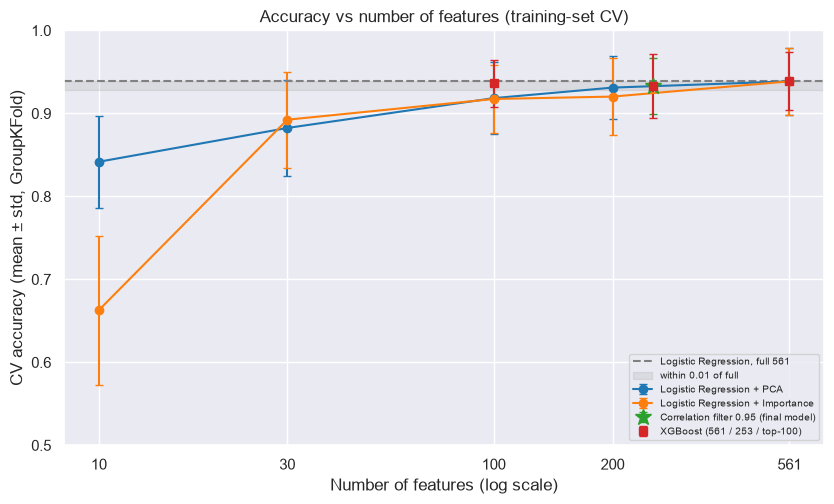

In [5]:
full_row = cv_summary.query("method == 'Full'").iloc[0]
full_acc = full_row.cv_accuracy

fig, ax = plt.subplots(figsize=(8.5, 5.2))
for method, color in [("PCA", "tab:blue"), ("Importance", "tab:orange")]:
    part = cv_summary[cv_summary.method == method].sort_values("budget")
    xs = list(part.budget) + [561]
    ys = list(part.cv_accuracy) + [full_acc]
    es = list(part.cv_std) + [full_row.cv_std]
    ax.errorbar(xs, ys, yerr=es, marker="o", capsize=3, color=color, label=f"Logistic Regression + {method}")

cf = cv_summary.query("method == 'Corr. filter'").iloc[0]
ax.errorbar([253], [cf.cv_accuracy], yerr=[cf.cv_std], marker="*", markersize=12, capsize=3,
            color="tab:green", linestyle="none", label="Correlation filter 0.95 (final model)")

xgb = cv_summary[cv_summary.method.str.startswith("XGB")]
ax.errorbar(xgb.budget, xgb.cv_accuracy, yerr=xgb.cv_std, fmt="s", capsize=3,
            color="tab:red", label="XGBoost (561 / 253 / top-100)")

ax.axhline(full_acc, color="gray", linestyle="--", label="Logistic Regression, full 561")
ax.axhspan(full_acc - 0.01, full_acc, color="gray", alpha=0.15, label="within 0.01 of full")
ax.set_xscale("log")
ax.set_xticks([10, 30, 100, 200, 561])
ax.set_xticklabels(["10", "30", "100", "200", "561"])
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_ylim(0.5, 1.0)                                      # the axis starts at 0.5: say so in the caption
ax.set_xlabel("Number of features (log scale)")
ax.set_ylabel("CV accuracy (mean ± std, GroupKFold)")
ax.set_title("Accuracy vs number of features (training-set CV)")
ax.legend(loc="lower right", fontsize=7)
plt.tight_layout()
plt.savefig("../reports/figures/feature_budget_cv.png", dpi=150)
plt.show()

In [6]:
X_test, y_test, s_test = load_split("test")
y_test0 = y_test - 1

def log_pipeline(pipe):
    trusted = sio.get_untrusted_types(data=sio.dumps(pipe))
    mlflow.sklearn.log_model(pipe, name="model", skops_trusted_types=trusted)

PROJECT_ROOT = Path.cwd().parent
mlflow.set_tracking_uri(f"sqlite:///{(PROJECT_ROOT / 'mlflow.db').as_posix()}")
mlflow.set_experiment("ActivityLens-M7-feature-budget")

test_rows, preds = [], {}
for method, k in configs:
    pipe = build(method, k).fit(X_train, y0)
    pred = pipe.predict(X_test)
    preds[(method, k)] = pred
    acc = accuracy_score(y_test0, pred)
    f1 = f1_score(y_test0, pred, average="macro")
    cm = confusion_matrix(y_test0, pred, labels=[0, 1, 2, 3, 4, 5])
    sit_stand = int(cm[3, 4] + cm[4, 3])                   # SITTING <-> STANDING errors
    total_errors = int((pred != y_test0.to_numpy()).sum())
    test_rows.append({"method": method, "budget": k, "test_accuracy": acc, "test_macro_f1": f1,
                      "sitting_standing_errors": sit_stand, "total_errors": total_errors})

    cv_row = cv_summary[(cv_summary.method == method) & (cv_summary.budget == k)].iloc[0]
    with mlflow.start_run(run_name=f"{method} | {k} features"):
        mlflow.log_params({"method": method, "budget": k, "cv": "GroupKFold(n_splits=5)"})
        mlflow.log_metrics({"cv_accuracy_mean": float(cv_row.cv_accuracy),
                            "cv_accuracy_std": float(cv_row.cv_std),
                            "test_accuracy": float(acc), "test_macro_f1": float(f1),
                            "sitting_standing_errors": sit_stand})
        log_pipeline(pipe)
    print(f"{method:17s} {k:>4d}: test accuracy {acc:.4f} | sitting<->standing errors {sit_stand} of {total_errors}")

2026/10/25 17:32:27 INFO mlflow.tracking.fluent: Experiment with name 'ActivityLens-M7-feature-budget' does not exist. Creating a new experiment.


Full               561: test accuracy 0.9610 | sitting<->standing errors 68 of 115
Corr. filter       253: test accuracy 0.9481 | sitting<->standing errors 89 of 153
PCA                200: test accuracy 0.9457 | sitting<->standing errors 87 of 160
PCA                100: test accuracy 0.9338 | sitting<->standing errors 94 of 195
PCA                 30: test accuracy 0.8904 | sitting<->standing errors 130 of 323
PCA                 10: test accuracy 0.8405 | sitting<->standing errors 242 of 470
Importance         200: test accuracy 0.9505 | sitting<->standing errors 97 of 146
Importance         100: test accuracy 0.9209 | sitting<->standing errors 150 of 233
Importance          30: test accuracy 0.8582 | sitting<->standing errors 191 of 418
Importance          10: test accuracy 0.5487 | sitting<->standing errors 158 of 1330
XGB Full           561: test accuracy 0.9511 | sitting<->standing errors 84 of 144
XGB Corr. filter   253: test accuracy 0.9549 | sitting<->standing errors 71 of 13

          method  budget  cv_accuracy  cv_std  cv_f1_macro  test_accuracy  test_macro_f1  sitting_standing_errors  total_errors
            Full     561       0.9387  0.0404       0.9372         0.9610         0.9609                       68           115
    Corr. filter     253       0.9331  0.0340       0.9326         0.9481         0.9481                       89           153
             PCA     200       0.9311  0.0375       0.9301         0.9457         0.9458                       87           160
             PCA     100       0.9184  0.0431       0.9169         0.9338         0.9323                       94           195
             PCA      30       0.8825  0.0574       0.8812         0.8904         0.8881                      130           323
             PCA      10       0.8418  0.0553       0.8411         0.8405         0.8378                      242           470
      Importance     200       0.9203  0.0466       0.9195         0.9505         0.9503                

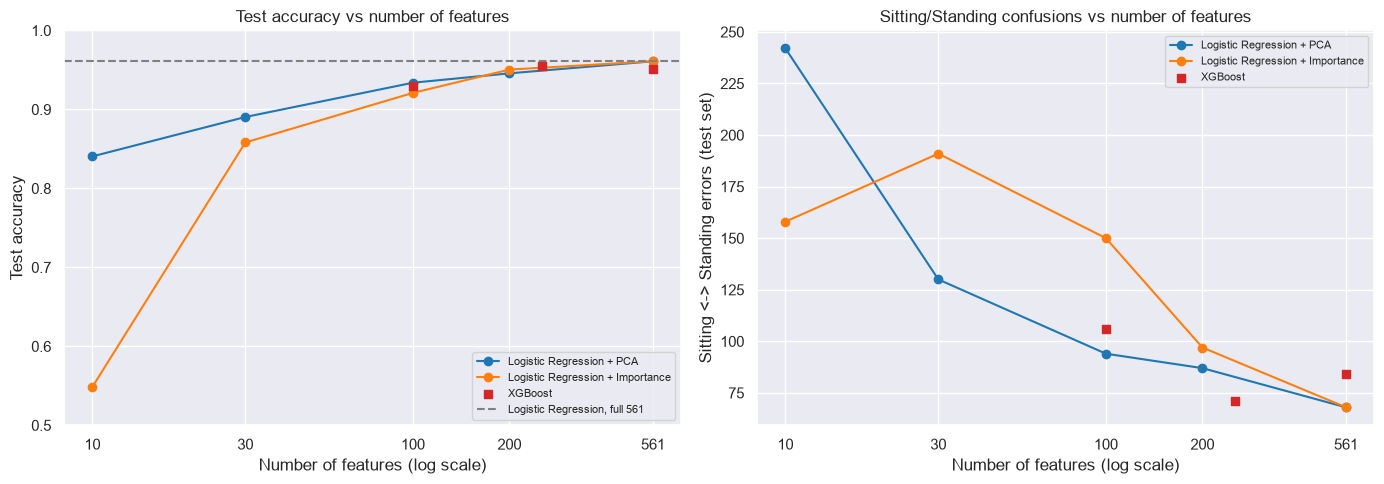

In [7]:
results = cv_summary.merge(pd.DataFrame(test_rows), on=["method", "budget"])
print(results.round(4).to_string(index=False))
results.to_csv("../reports/m7_feature_budget_results.csv", index=False)

full_test = results.query("method == 'Full'").iloc[0]
xgb_t = results[results.method.str.startswith("XGB")]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for method, color in [("PCA", "tab:blue"), ("Importance", "tab:orange")]:
    part = results[results.method == method].sort_values("budget")
    xs = list(part.budget) + [561]
    axes[0].plot(xs, list(part.test_accuracy) + [full_test.test_accuracy], marker="o", color=color,
                 label=f"Logistic Regression + {method}")
    axes[1].plot(xs, list(part.sitting_standing_errors) + [full_test.sitting_standing_errors],
                 marker="o", color=color, label=f"Logistic Regression + {method}")

axes[0].scatter(xgb_t.budget, xgb_t.test_accuracy, marker="s", color="tab:red", zorder=5, label="XGBoost")
axes[1].scatter(xgb_t.budget, xgb_t.sitting_standing_errors, marker="s", color="tab:red", zorder=5, label="XGBoost")
axes[0].axhline(full_test.test_accuracy, color="gray", linestyle="--", label="Logistic Regression, full 561")
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Test accuracy vs number of features")
axes[0].set_ylim(0.5, 1.0)
axes[1].set_ylabel("Sitting <-> Standing errors (test set)")
axes[1].set_title("Sitting/Standing confusions vs number of features")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks([10, 30, 100, 200, 561])
    ax.set_xticklabels(["10", "30", "100", "200", "561"])
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.set_xlabel("Number of features (log scale)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("../reports/figures/feature_budget_test.png", dpi=150)
plt.show()

In [8]:
rng = np.random.default_rng(RANDOM_STATE)
y_true = y_test0.to_numpy()
vols = np.sort(s_test.unique())
masks = [(s_test == v).to_numpy() for v in vols]
n_per = np.array([m.sum() for m in masks])

def correct_per_volunteer(pred):
    return np.array([(pred[m] == y_true[m]).sum() for m in masks])

comparisons = [
    (("XGB Full", 561), ("XGB Importance", 100), "XGBoost: full 561 minus importance top-100"),
    (("Full", 561), ("Importance", 100), "Logistic Regression: full 561 minus importance top-100"),
    (("Full", 561), ("Corr. filter", 253), "Logistic Regression: full 561 minus correlation filter 253"),
    (("XGB Full", 561), ("Corr. filter", 253), "XGBoost full 561 minus final model (Logistic Regression, 253)"),
]

B = 10000
idx = rng.integers(0, len(vols), size=(B, len(vols)))     # resample the 9 test volunteers with replacement
for a, b, name in comparisons:
    ca, cb = correct_per_volunteer(preds[a]), correct_per_volunteer(preds[b])
    diff = (ca[idx].sum(axis=1) - cb[idx].sum(axis=1)) / n_per[idx].sum(axis=1)
    lo, hi = np.percentile(diff, [2.5, 97.5])
    observed = (ca.sum() - cb.sum()) / n_per.sum()
    print(f"{name}: observed {observed * 100:+.2f} points, 95% CI [{lo * 100:+.2f}, {hi * 100:+.2f}]")

XGBoost: full 561 minus importance top-100: observed +2.14 points, 95% CI [+0.99, +3.27]
Logistic Regression: full 561 minus importance top-100: observed +4.00 points, 95% CI [+2.00, +6.28]
Logistic Regression: full 561 minus correlation filter 253: observed +1.29 points, 95% CI [+0.33, +2.34]
XGBoost full 561 minus final model (Logistic Regression, 253): observed +0.31 points, 95% CI [-1.25, +1.97]
